In [133]:
import torch
from typing import Sequence, Dict
import matplotlib.pyplot as plt

In [134]:

def lorenz63(xyz, sigma=10.0, rho=28.0, beta=8/3):
    x, y, z = xyz[..., 0], xyz[..., 1], xyz[..., 2]
    dx = sigma * (y - x)
    dy = x * (rho - z) - y
    dz = x * y - beta * z
    return torch.stack([dx, dy, dz], dim=-1)

def rk4_step(func, state, dt, **kwargs):
    k1 = func(state, **kwargs)
    k2 = func(state + 0.5 * dt * k1, **kwargs)
    k3 = func(state + 0.5 * dt * k2, **kwargs)
    k4 = func(state + dt * k3, **kwargs)
    return state + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

def generate_lorenz63(n_steps=10000, dt=0.01, 
                      sigma=10.0, rho=28.0, beta=8/3,
                      device="cpu"):
    # initial condition
    state = torch.tensor([[1.0, 1.0, 1.0]], device=device)
    traj = [state]
    for _ in range(n_steps):
        state = rk4_step(lorenz63, state, dt, sigma=sigma, rho=rho, beta=beta)
        traj.append(state)
    return torch.cat(traj)

# Example usage
if __name__ == "__main__":
    burnin = 200 
    traj = generate_lorenz63(n_steps=2000+burnin, dt=0.01)
    print(traj.shape)  # (10001, 3)

torch.Size([2201, 3])


In [135]:
def rbf_kernel(X: torch.Tensor, Y: torch.Tensor, lengthscale: float = 1.0, variance: float = 1.0) -> torch.Tensor:
    """
    Radial Basis Function (Gaussian) kernel supporting broadcasting:
      X: (..., d), Y: (..., d) -> output: broadcasted leading shape
    """
    # X, Y are broadcast to a common shape (..., d)
    diff = X - Y
    sqdist = (diff * diff).sum(dim=-1)
    ls2 = (float(lengthscale) ** 2) + 1e-12
    return float(variance) * torch.exp(-0.5 * sqdist / ls2)

def additive_rbf_kernel(
    X: torch.Tensor,
    Y: torch.Tensor,
    lengthscales: Sequence[float],
    variances: Sequence[float],
    eps: float = 1e-12,
) -> torch.Tensor:
    """
    Additive RBF kernel: a linear combination of multiple Gaussian kernels
      k(x,y) = Σ_m variances[m] * exp( -0.5 * ||x - y||^2 / lengthscales[m]^2 )

    Parameters
    ----------
    X, Y : (N, d) tensors (broadcastable inputs)
        Input arrays of points.
    lengthscales : list or 1D tensor of floats
        Lengthscales ℓ_m for each component.
    variances : list or 1D tensor of floats
        Variances σ_m² for each component.
    eps : float
        Small constant to stabilize divisions.

    Returns
    -------
    K : (N, M) tensor
        Kernel matrix between all pairs of rows in X and Y.
    """
    X = torch.as_tensor(X)
    Y = torch.as_tensor(Y)
    device, dtype = X.device, X.dtype

    lengthscales = torch.as_tensor(lengthscales, dtype=dtype, device=device)
    variances = torch.as_tensor(variances, dtype=dtype, device=device)
    assert lengthscales.shape == variances.shape, "lengthscales and variances must have same length"

    diff = X[:, None, :] - Y[None, :, :]     # (N, M, d)
    sqdist = (diff ** 2).sum(dim=-1, keepdim=False)  # (N, M)

    # Vectorized additive sum over all components
    K = torch.zeros_like(sqdist)
    for ℓ, σ2 in zip(lengthscales, variances):
        K += σ2 * torch.exp(-0.5 * sqdist / (ℓ ** 2 + eps))
    return K

In [136]:
def make_delay_matrix(v_train: torch.Tensor, tau: int):
    train_size = v_train.numel()
    assert tau < train_size, "tau must be smaller than train_size"

    # reverse the series to make slicing easier
    v_rev = torch.flip(v_train, dims=[0])

    # build a list of shifted versions
    X = torch.stack([v_rev[i : i + train_size - tau] for i in range(tau + 1)], dim=1)

    # X has rows corresponding to reversed indexing, so flip rows back
    X = torch.flip(X, dims=[0])
    return X


In [157]:
burnin = 200
dt = 0.01
n_tot = 2000
train_size = 1000
v_train = traj[burnin:burnin+train_size,0]
v_test = traj[burnin+train_size:burnin+train_size+n_tot+1,0]
tau = 3
train_times = dt*torch.arange(burnin,burnin+train_size)
test_times = dt*torch.arange(burnin+train_size,burnin+n_tot+1)
Y_train = (traj[burnin+1+tau:burnin+1+train_size,0]-traj[burnin+tau:burnin+train_size,0])/dt

In [158]:
Y_test = (traj[burnin+train_size:,0]-traj[burnin+train_size-1:-1,0])/dt

In [159]:
torch.arange(burnin+train_size,burnin+n_tot+1).shape

torch.Size([1001])

In [160]:
v_test.shape

torch.Size([1001])

In [161]:
test_times.shape

torch.Size([1001])

In [162]:
def gaussian_kernel(x, y, sigma=1.0):
    """
    Computes standard Gaussian (RBF) kernel between two 1D tensors x and y.
    Returns a matrix of shape (len(x), len(y)).
    """
    x = x.unsqueeze(1)  # (n,1)
    y = y.unsqueeze(0)  # (1,m)
    return torch.exp(-0.5 * (x - y)**2 / sigma**2)


In [163]:
def G_single(v, s, w, t, sigma_F=1.0, sigma_K1=1.0, sigma_K2=1.0):
    """
    Computes scalar G((v,s),(w,t)) for matching 1D vectors v,w,s,t (each length tau+1).
    """
    # First term
    G_F = torch.exp(-0.5 * (v[0] - w[0])**2 / sigma_F**2)

    # Reverse for K2 part
    v_flip = torch.flip(v, dims=[0])
    w_flip = torch.flip(w, dims=[0])

    K1 = gaussian_kernel(s, t, sigma_K1)
    K2 = gaussian_kernel(v_flip, w_flip, sigma_K2)

    return G_F + torch.sum(K1 * K2)


def G_MATRIX(V, W, S, T, sigma_F=1.0, sigma_K1=1.0, sigma_K2=1.0):
    """
    Full Gram matrix: shape (N, M)
    """
    N, _ = V.shape
    M, _ = W.shape

    # Expand for pairwise combinations
    v_exp = V[:, None, :]       # (N, 1, tau+1)
    w_exp = W[None, :, :]       # (1, M, tau+1)
    s_exp = S[:, None, :]
    t_exp = T[None, :, :]

    # G_F term (pairwise between v0 and w0)
    G_F = torch.exp(-0.5 * (v_exp[..., 0] - w_exp[..., 0])**2 / sigma_F**2)  # (N, M)

    # Flipped for K2
    v_flip = torch.flip(v_exp, dims=[-1])
    w_flip = torch.flip(w_exp, dims=[-1])

    # Compute all K1 and K2 (N, M, τ+1, τ+1)

    K1 = torch.exp(-0.5 * (s_exp.unsqueeze(-2) - t_exp.unsqueeze(-3))**2 / sigma_K1**2)
    K2 = torch.exp(-0.5 * (v_flip.unsqueeze(-2) - w_flip.unsqueeze(-3))**2 / sigma_K2**2)

    # Sum over last two axes to get scalar per (N,M) pair
    sum_term = torch.sum(K1 * K2, dim=(-2, -1))

    return G_F + sum_term


In [164]:
def kernel_ridge_regression(X_train, S_train, Y_train, 
                            X_test, S_test,
                            sigma_F=1.0, sigma_K1=1.0, sigma_K2=1.0, 
                            reg_lambda=1e-6):
    """
    Compute Kernel Ridge Regression prediction using custom kernel G_MATRIX.
    
    Args:
        X_train: (N, tau+1)
        S_train: (N, tau+1)
        Y_train: (N,) or (N, d)
        X_test:  (M, tau+1)
        S_test:  (M, tau+1)
        reg_lambda: regularization parameter (λ)
        
    Returns:
        Y_pred: (M,) or (M, d)
    """
    N = X_train.shape[0]

    # ----- Kernel matrices -----
    K_train = G_MATRIX(X_train, X_train, S_train, S_train,
                       sigma_F, sigma_K1, sigma_K2)  # (N, N)
    K_cross = G_MATRIX(X_test, X_train, S_test, S_train,
                       sigma_F, sigma_K1, sigma_K2)  # (M, N)

    # ----- Regularization and solve -----
    I = torch.eye(N, device=X_train.device, dtype=X_train.dtype)
    A = K_train + reg_lambda * I

    # Solve for alpha = A^{-1} Y_train
    # Use Cholesky or torch.linalg.solve for stability
    alpha = torch.linalg.solve(A, Y_train)

    # ----- Prediction -----
    Y_pred = K_cross @ alpha
    return Y_pred

In [165]:
X = make_delay_matrix(v_train,tau)
T = make_delay_matrix(train_times,tau)

In [166]:
X_test = make_delay_matrix(v_test,tau)
T_test = make_delay_matrix(test_times,tau)

In [167]:
Y_train.shape

torch.Size([997])

In [168]:
X.shape

torch.Size([997, 4])

In [169]:
T.shape

torch.Size([997, 4])

In [170]:
X_test.shape

torch.Size([998, 4])

In [171]:
T_test.shape

torch.Size([998, 4])

In [172]:
Y_train

tensor([-1.4565e+01, -1.4443e+01, -1.4166e+01, -1.3726e+01, -1.3120e+01,
        -1.2345e+01, -1.1403e+01, -1.0297e+01, -9.0359e+00, -7.6309e+00,
        -6.0973e+00, -4.4541e+00, -2.7238e+00, -9.3174e-01,  8.9445e-01,
         2.7254e+00,  4.5309e+00,  6.2813e+00,  7.9476e+00,  9.5032e+00,
         1.0924e+01,  1.2189e+01,  1.3282e+01,  1.4191e+01,  1.4907e+01,
         1.5426e+01,  1.5748e+01,  1.5877e+01,  1.5820e+01,  1.5587e+01,
         1.5189e+01,  1.4640e+01,  1.3954e+01,  1.3145e+01,  1.2230e+01,
         1.1222e+01,  1.0137e+01,  8.9866e+00,  7.7848e+00,  6.5429e+00,
         5.2715e+00,  3.9803e+00,  2.6779e+00,  1.3721e+00,  7.0047e-02,
        -1.2218e+00, -2.4976e+00, -3.7515e+00, -4.9781e+00, -6.1720e+00,
        -7.3275e+00, -8.4385e+00, -9.4990e+00, -1.0502e+01, -1.1440e+01,
        -1.2305e+01, -1.3089e+01, -1.3781e+01, -1.4371e+01, -1.4850e+01,
        -1.5205e+01, -1.5427e+01, -1.5504e+01, -1.5426e+01, -1.5183e+01,
        -1.4768e+01, -1.4175e+01, -1.3400e+01, -1.2

In [187]:
Y_pred = kernel_ridge_regression(X,T,Y_train, X_test, T_test,
                                 sigma_F=1, sigma_K1=1, sigma_K2=1, reg_lambda=1e3)

In [188]:
Y_test[3:]-Y_pred

tensor([ 7.3100e+00,  5.0960e+00,  2.9919e+00,  9.8399e-01, -9.4241e-01,
        -2.8024e+00, -4.6117e+00, -6.3856e+00, -8.1394e+00, -9.8880e+00,
        -1.1645e+01, -1.3424e+01, -1.5238e+01, -1.7095e+01, -1.9006e+01,
        -2.0976e+01, -2.3011e+01, -2.5112e+01, -2.7281e+01, -2.9514e+01,
        -3.1810e+01, -3.4163e+01, -3.6563e+01, -3.8998e+01, -4.1437e+01,
        -4.3837e+01, -4.6130e+01, -4.8238e+01, -5.0075e+01, -5.1543e+01,
        -5.2524e+01, -5.2877e+01, -5.2453e+01, -5.1113e+01, -4.8734e+01,
        -4.5217e+01, -4.0502e+01, -3.4573e+01, -2.7477e+01, -1.9329e+01,
        -1.0313e+01, -6.8165e-01,  9.2606e+00,  1.9174e+01,  2.8712e+01,
         3.7549e+01,  4.5407e+01,  5.2083e+01,  5.7453e+01,  6.1466e+01,
         6.4129e+01,  6.5486e+01,  6.5625e+01,  6.4693e+01,  6.2861e+01,
         6.0285e+01,  5.7113e+01,  5.3507e+01,  4.9631e+01,  4.5625e+01,
         4.1601e+01,  3.7641e+01,  3.3805e+01,  3.0132e+01,  2.6644e+01,
         2.3357e+01,  2.0276e+01,  1.7403e+01,  1.4

In [178]:
Y_pred

tensor([ 1.3859e+01,  1.5344e+01,  1.5969e+01,  1.6242e+01,  1.5875e+01,
         1.5414e+01,  1.4156e+01,  1.2781e+01,  1.1203e+01,  8.8438e+00,
         6.2812e+00,  4.0000e+00,  1.6719e+00, -2.6562e-01, -1.1562e+00,
        -1.7188e+00, -2.7812e+00, -2.7812e+00, -4.1250e+00, -5.1406e+00,
        -4.8125e+00, -5.6719e+00, -6.4688e+00, -6.3438e+00, -7.4219e+00,
        -7.0391e+00, -6.5781e+00, -6.5625e+00, -6.2969e+00, -6.0000e+00,
        -5.0156e+00, -3.8281e+00, -2.4688e+00, -1.2500e+00, -4.6875e-02,
         1.7656e+00,  2.6094e+00,  3.3047e+00,  3.7031e+00,  3.5234e+00,
         3.4844e+00,  3.4453e+00,  3.3203e+00,  3.3086e+00,  2.7500e+00,
         2.1953e+00,  4.3750e-01, -7.6562e-01, -2.1406e+00, -3.5156e+00,
        -4.9688e+00, -6.0273e+00, -6.6250e+00, -6.9531e+00, -7.2969e+00,
        -7.7266e+00, -7.3750e+00, -6.1328e+00, -5.3125e+00, -4.0781e+00,
        -3.0469e+00, -1.6719e+00,  1.5938e+00,  6.3750e+00,  1.2094e+01,
         1.7812e+01,  2.1531e+01,  2.3742e+01,  2.4

In [126]:
v_pred = torch.zeros(len(v_test))
v_pred[0] = v_train[-1]+dt*Y_pred[0]+dt*eta_test[0]

In [127]:
for i in range(tau,len(v_test)-tau):
    v_pred[i] = v_pred[i-1]+dt*Y_pred[i-tau]+dt*eta_test[i-tau]

/var/folders/7x/mpmr_n_96hv_7fkxygr63wg80000gn/T/ipykernel_53014/3986364975.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


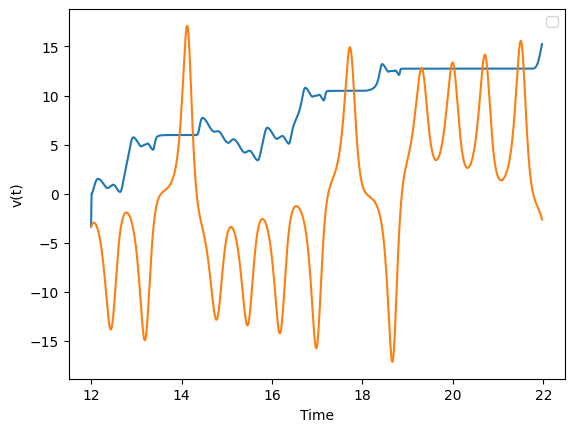

In [128]:
plt.plot(test_times[:-tau], v_pred[:-tau])
plt.plot(test_times[:-tau], v_test[:-tau])
plt.xlabel('Time')
plt.ylabel('v(t)')
plt.legend()
plt.show()

In [427]:
v_pred

tensor([-1.5553,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000])